<a href="https://colab.research.google.com/github/mhage82/ARI510/blob/main/lab2_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARI 410/510 Lab 2 Starter Notebook

This notebook only gets the data loaded for you: it downloads and unzips the dataset, reads the provided train and test files, and attaches the activity names and feature names. Everything after that is the lab.

**How to use this:** In Colab, *File → Save a copy in Drive*, then run top to bottom.

## 0. Get the data

Either download it directly (next cell), or download the zip from Canvas and upload it to Colab's file panel (left sidebar), then set `ZIP_PATH` to its name.

Note: the download is a zip *inside* a zip. The helper below handles that for you.

In [1]:
import os, zipfile, glob, urllib.request
from pathlib import Path

ZIP_PATH = "UCI_HAR_Dataset.zip"   # change this if you uploaded the file under a different name
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

if not os.path.exists(ZIP_PATH):
    try:
        print("Downloading from UCI...")
        urllib.request.urlretrieve(URL, ZIP_PATH)
    except Exception as e:
        print("Download failed:", e, "\nUpload the zip from Canvas instead and set ZIP_PATH.")

# Unzip the outer zip, then the inner 'UCI HAR Dataset.zip'
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("har_raw")
inner = glob.glob("har_raw/**/UCI HAR Dataset.zip", recursive=True)
if inner:
    with zipfile.ZipFile(inner[0]) as z:
        z.extractall("har_raw")
# DATA = glob.glob("har_raw/**/UCI HAR Dataset/train", recursive=True)[0].rsplit("/train", 1)[0] + "/"
train_folder = Path(glob.glob("har_raw/**/UCI HAR Dataset/train", recursive=True)[0])
DATA = str(train_folder.parent) + os.sep
print("Data folder:", DATA)

Data folder: har_raw\UCI HAR Dataset\


## 1. Load the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
BASE_PATH = Path.cwd()

# Feature names. Some names appear more than once in features.txt, so we add
# a numeric suffix to duplicates to keep every name unique.
raw_names = pd.read_csv(str(BASE_PATH)+"\\"+ DATA + "features.txt", sep=r"\s+", header=None)[1].tolist()
seen, feature_names = {}, []
for n in raw_names:
    seen[n] = seen.get(n, 0) + 1
    feature_names.append(n if seen[n] == 1 else f"{n}__{seen[n]}")

# Map integer labels (1-6) to activity names
label_map = dict(pd.read_csv(DATA + "activity_labels.txt", sep=r"\s+", header=None).values)

def load(split):
    X = pd.read_csv(DATA + f"{split}/X_{split}.txt", sep=r"\s+", header=None).values
    y = pd.read_csv(DATA + f"{split}/y_{split}.txt", header=None)[0].map(label_map).values
    return X, y

X_train_full, y_train_full = load("train")
X_train, X_dev, y_train, y_dev = train_test_split(X_train_full, 
                                                  y_train_full, 
                                                  test_size=0.2, 
                                                  random_state=42, 
                                                  stratify=y_train_full)
X_test, y_test = load("test")
print("train:", X_train.shape, " dev:", X_dev.shape, " test:", X_test.shape)
print("activities:", sorted(set(y_train)))

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)


train: (5881, 561)  dev: (1471, 561)  test: (2947, 561)
activities: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


## Plotting helpers

Making plots isn't the point of this lab, so here are three general-purpose helpers. They're demonstrated below on **made-up toy data**; you'll call them with your own results. Feel free to modify them or write your own.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_bar(labels, title="", xlabel="", ylabel="count"):
    """Bar chart of how often each value in `labels` occurs."""
    counts = pd.Series(labels).value_counts()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    counts.plot(kind="bar", ax=ax)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

def plot_lines(x, series, title="", xlabel="", ylabel="", hline=None, hline_label=None, logx=False):
    """Line plot of one or more series against x.
    `series` is a dict {line name: list of y values (same length as x)}.
    Optionally draws a dashed horizontal reference line at y = hline."""
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, ys in series.items():
        ax.plot(x, ys, marker="o", label=name)
    if hline is not None:
        ax.axhline(hline, linestyle="--", color="gray", label=hline_label)
    if logx:
        ax.set_xscale("log")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    if len(series) > 1 or hline_label:
        ax.legend()
    plt.tight_layout(); plt.show()

def scatter_2d(Z, labels, title="", xlabel="", ylabel=""):
    """Scatter plot of the first two columns of Z, one color per value in `labels`."""
    Z, labels = np.asarray(Z), np.asarray(labels)
    fig, ax = plt.subplots(figsize=(7, 5))
    for lab in sorted(set(labels), key=str):
        m = labels == lab
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, label=str(lab))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

def scatter_3d(Z, labels, title="", xlabel="", ylabel="", zlabel=""):   
    """3D scatter plot of the first three columns of Z, one color per value in `labels`."""
    from mpl_toolkits.mplot3d import Axes3D
    Z, labels = np.asarray(Z), np.asarray(labels)
    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111, projection="3d")
    for lab in sorted(set(labels), key=str):
        m = labels == lab
        ax.scatter(Z[m, 0], Z[m, 1], Z[m, 2], s=5, alpha=0.5, label=str(lab))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_zlabel(zlabel)
    ax.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

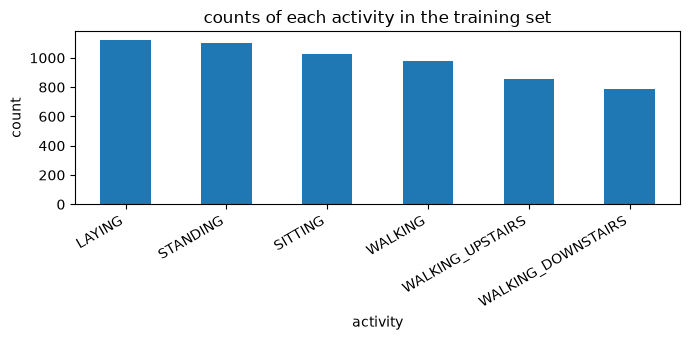

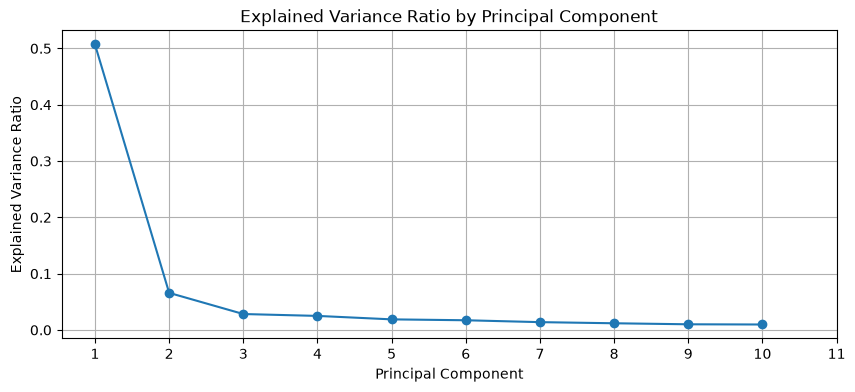

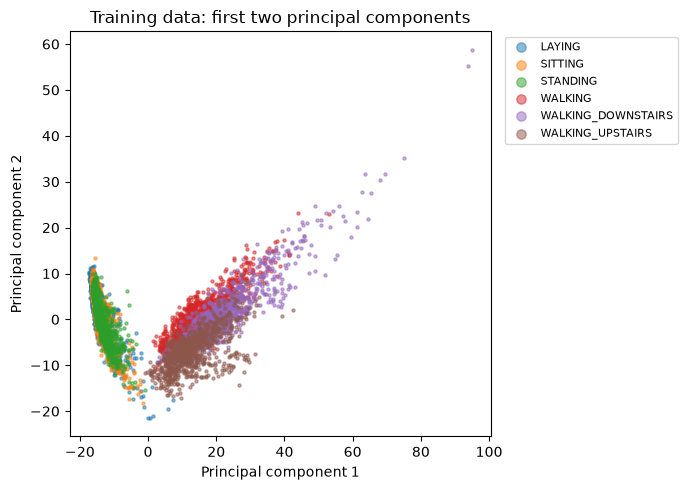

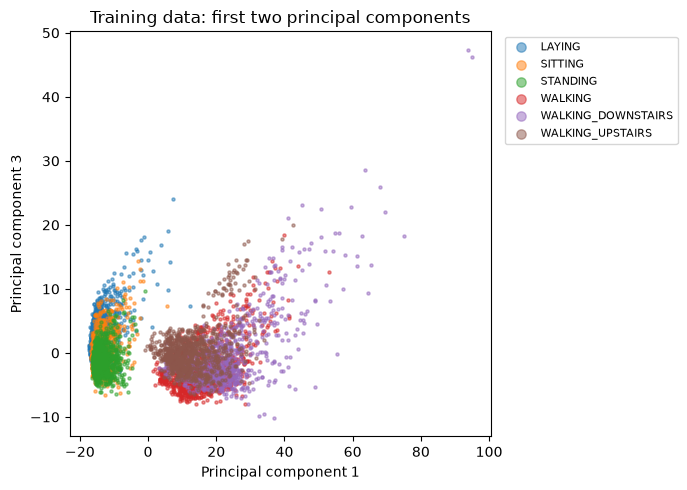

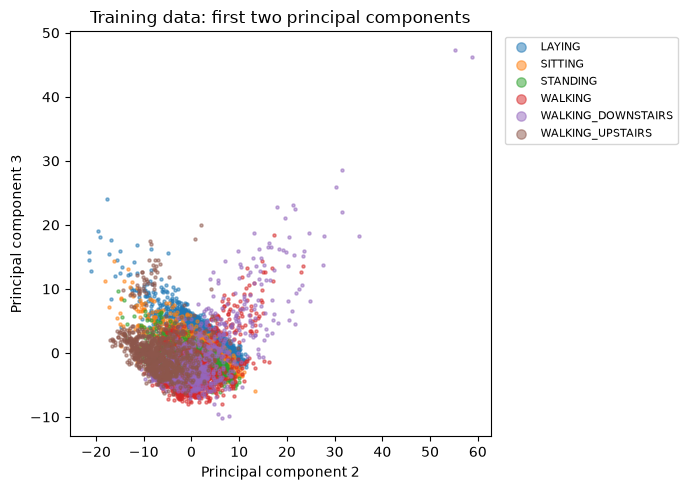

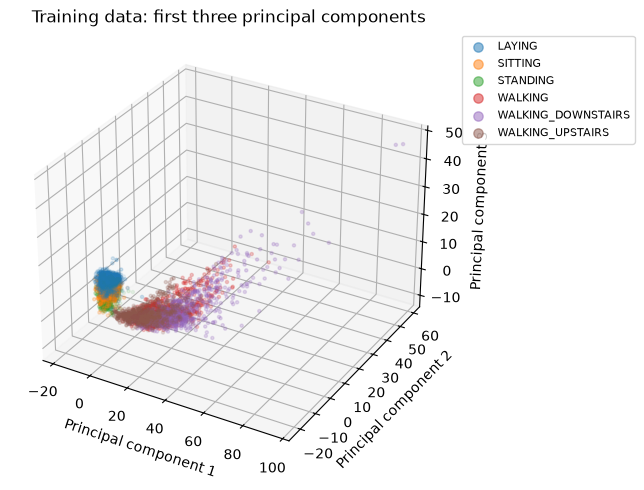

In [4]:

plot_bar(y_train, 
         title="counts of each activity in the training set", 
         xlabel="activity",
         ylabel="count")

from sklearn.decomposition import PCA

pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)

n_show = 10
plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, n_show+1), 
         pca.explained_variance_ratio_[:n_show],
         marker="o")
plt.xticks(np.arange(1, n_show+2))
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance Ratio by Principal Component")
plt.grid(True)
plt.show()

scatter_2d(
    X_train_pca,
    y_train,
    title="Training data: first two principal components",
    xlabel="Principal component 1",
    ylabel="Principal component 2"
)

# plot PC1, PC3
scatter_2d(
    X_train_pca[:,[0, 2]],
    y_train,
    title="Training data: first two principal components",
    xlabel="Principal component 1",
    ylabel="Principal component 3"
)

# plot PC2, PC3
scatter_2d(
    X_train_pca[:,[1, 2]],
    y_train,
    title="Training data: first two principal components",
    xlabel="Principal component 2",
    ylabel="Principal component 3"
)

scatter_3d(
    X_train_pca,
    y_train,
    title="Training data: first three principal components",
    xlabel="Principal component 1",
    ylabel="Principal component 2",
    zlabel="Principal component 3"
)



## Clustering
- Apply K-Means clustering
- Apply DBscan

Clusters: 2, Silhouette Score: 0.3925
Clusters: 3, Silhouette Score: 0.3344
Clusters: 4, Silhouette Score: 0.2757
Clusters: 5, Silhouette Score: 0.1258
Clusters: 6, Silhouette Score: 0.1063
Clusters: 7, Silhouette Score: 0.1012
Clusters: 8, Silhouette Score: 0.0882
Clusters: 9, Silhouette Score: 0.0802
Clusters: 10, Silhouette Score: 0.0832


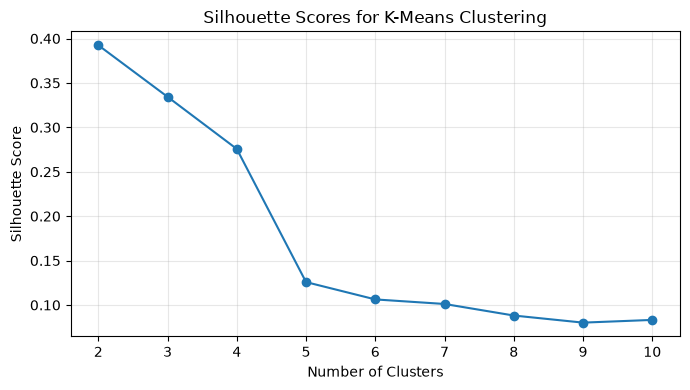

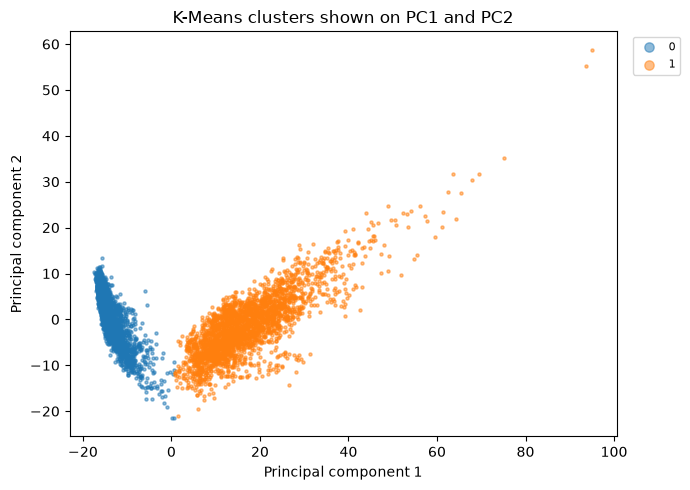

Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Cluster,,,,,,
0,1116,1028,1099,0,0,5
1,9,1,0,981,789,853


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_range = range(2, 11)
silhouette_scores = []

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_train_scaled)
    score = silhouette_score(X_train_scaled, 
                                        cluster_labels,
                                        sample_size=2000,
                                        random_state=42)
    silhouette_scores.append(score)
    print(f"Clusters: {n_clusters}, Silhouette Score: {score:.4f}")

plot_lines( list(cluster_range),
            {"K-Means": silhouette_scores},
            title="Silhouette Scores for K-Means Clustering",
            xlabel="Number of Clusters",
            ylabel="Silhouette Score")

best_n_clusters = 2

kmeans = KMeans(
    n_clusters=best_n_clusters,
    random_state=42,
    n_init=10
)
cluster_labels = kmeans.fit_predict(X_train_scaled)

scatter_2d(
    X_train_pca,
    cluster_labels,
    title="K-Means clusters shown on PC1 and PC2",
    xlabel="Principal component 1",
    ylabel="Principal component 2"
)
pd.crosstab(
    cluster_labels,
    y_train,
    rownames=["Cluster"],
    colnames=["Activity"]
)




## Clustering for PC1 PC3

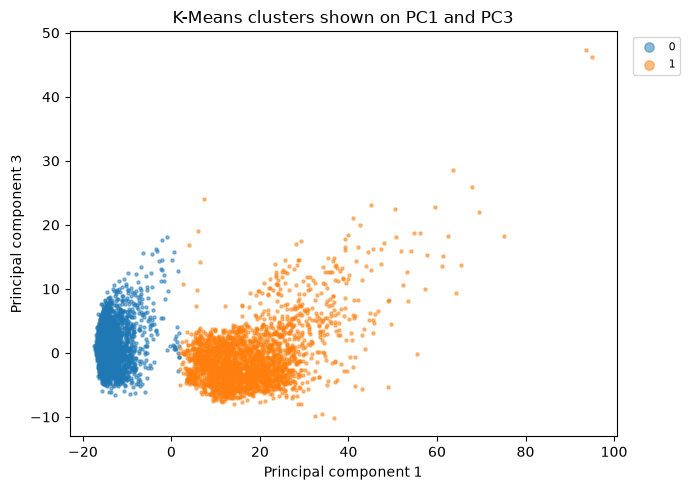

Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Cluster,,,,,,
0,1118,1028,1099,1,0,16
1,7,1,0,980,789,842


In [6]:

X_pc1_pc3 = X_train_pca[:, [0, 2]]
kmeans_pc1_pc3 = KMeans(
    n_clusters=best_n_clusters,
    random_state=42,
    n_init=10
)
cluster_labels_pc1_pc3 = kmeans_pc1_pc3.fit_predict(X_pc1_pc3)

scatter_2d(
    X_pc1_pc3,
    cluster_labels_pc1_pc3,
    title="K-Means clusters shown on PC1 and PC3",
    xlabel="Principal component 1",
    ylabel="Principal component 3"
)
pd.crosstab(
    cluster_labels_pc1_pc3,
    y_train,
    rownames=["Cluster"],
    colnames=["Activity"]
)



## DBSCAN

DBSCAN with eps=5:
Number of clusters: 0
Number of noise points: 5881
DBSCAN with eps=10:
Number of clusters: 15
Number of noise points: 4432
DBSCAN with eps=15:
Number of clusters: 8
Number of noise points: 1215
DBSCAN with eps=20:
Number of clusters: 2
Number of noise points: 255
DBSCAN with eps=25:
Number of clusters: 1
Number of noise points: 100
DBSCAN with eps=30:
Number of clusters: 1
Number of noise points: 34


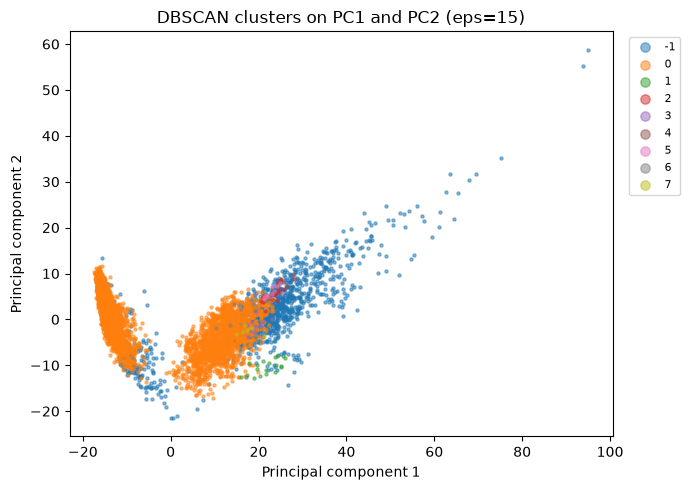

Activity counts for eps=15:


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
DBSCAN cluster,,,,,,
-1,105,74,28,203,603,202
0,1020,955,1071,735,175,631
1,0,0,0,0,0,19
2,0,0,0,20,0,0
3,0,0,0,0,11,0
4,0,0,0,5,0,0
5,0,0,0,10,0,0
6,0,0,0,8,0,0
7,0,0,0,0,0,6


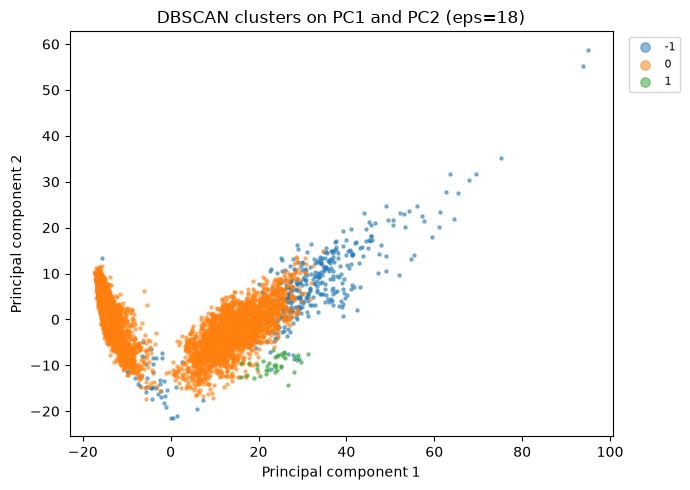

Activity counts for eps=18:


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
DBSCAN cluster,,,,,,
-1,43,12,4,69,260,53
0,1082,1017,1095,912,529,768
1,0,0,0,0,0,37


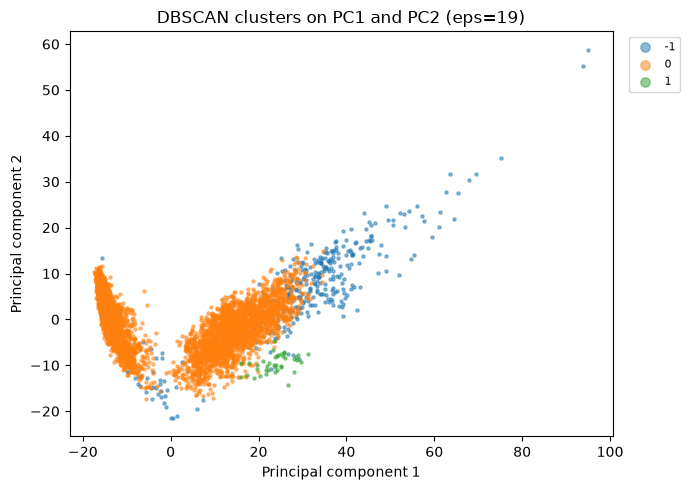

Activity counts for eps=19:


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
DBSCAN cluster,,,,,,
-1,34,8,3,56,208,40
0,1091,1021,1096,925,581,779
1,0,0,0,0,0,39


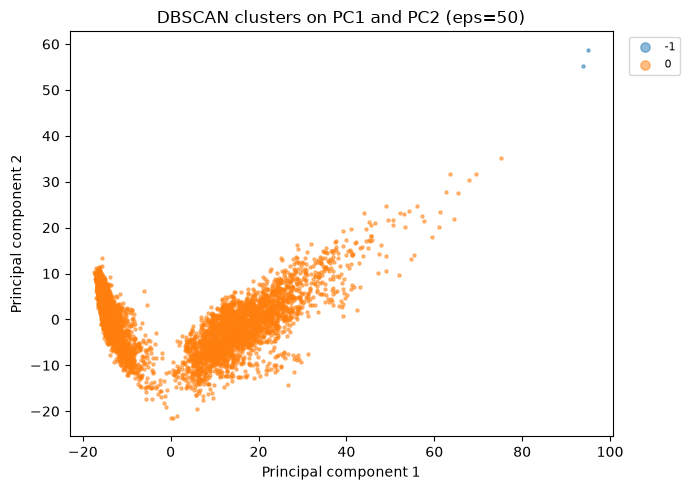

Activity counts for eps=50:


Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
DBSCAN cluster,,,,,,
-1,0,0,0,0,2,0
0,1125,1029,1099,981,787,858


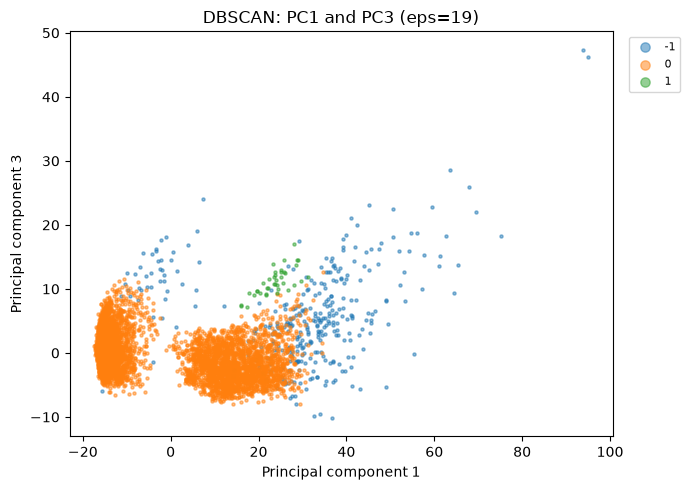

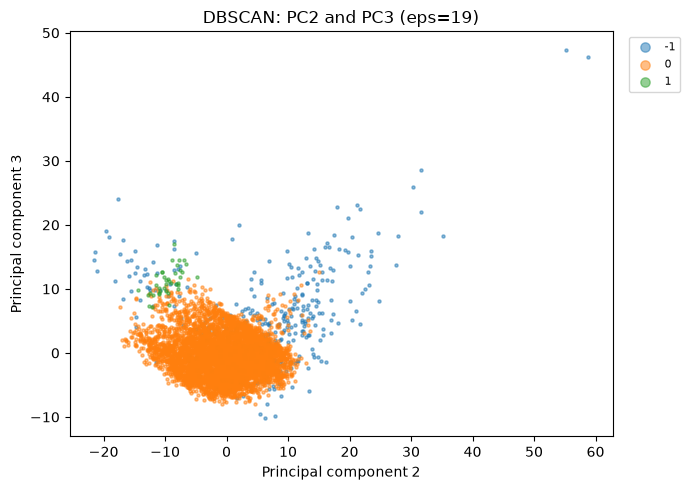

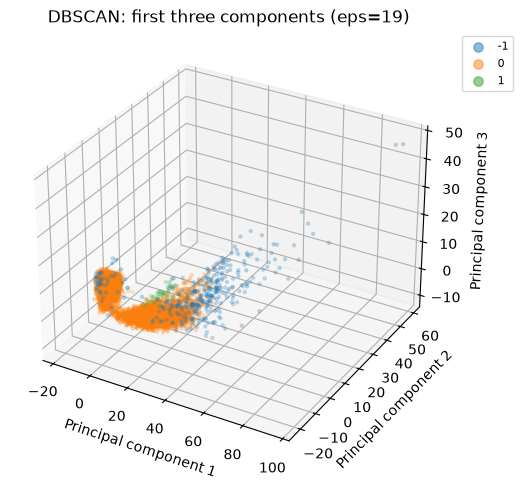

In [7]:
from sklearn.cluster import DBSCAN

eps_value = [5,10,15,20,25,30]

for eps in eps_value:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    cluster_labels_dbscan = dbscan.fit_predict(X_train_scaled)

    # Count the number of clusters (excluding noise points labeled as -1)
    n_clusters_dbscan = len(set(cluster_labels_dbscan)) - (1 if -1 in cluster_labels_dbscan else 0)
    n_noise_dbscan = list(cluster_labels_dbscan).count(-1)

    print(f"DBSCAN with eps={eps}:")
    print(f"Number of clusters: {n_clusters_dbscan}")
    print(f"Number of noise points: {n_noise_dbscan}")

for chosen_eps in [15, 18, 19, 50]:
    dbscan = DBSCAN(eps=chosen_eps, min_samples=5)
    labels = dbscan.fit_predict(X_train_scaled)

    scatter_2d(
        X_train_pca,
        labels,
        title=f"DBSCAN clusters on PC1 and PC2 (eps={chosen_eps})",
        xlabel="Principal component 1",
        ylabel="Principal component 2"
    )

    print(f"Activity counts for eps={chosen_eps}:")
    display(pd.crosstab(
        labels,
        y_train,
        rownames=["DBSCAN cluster"],
        colnames=["Activity"]
    ))

    # Fit DBSCAN for the setting you want to inspect
chosen_eps = 19
dbscan = DBSCAN(eps=chosen_eps, min_samples=5)
labels_eps19 = dbscan.fit_predict(X_train_scaled)

# PC1 and PC3
scatter_2d(
    X_train_pca[:, [0, 2]],
    labels_eps19,
    title="DBSCAN: PC1 and PC3 (eps=19)",
    xlabel="Principal component 1",
    ylabel="Principal component 3"
)

# PC2 and PC3
scatter_2d(
    X_train_pca[:, [1, 2]],
    labels_eps19,
    title="DBSCAN: PC2 and PC3 (eps=19)",
    xlabel="Principal component 2",
    ylabel="Principal component 3"
)

# PC1, PC2, and PC3
scatter_3d(
    X_train_pca,
    labels_eps19,
    title="DBSCAN: first three components (eps=19)",
    xlabel="Principal component 1",
    ylabel="Principal component 2",
    zlabel="Principal component 3"
)

## PCA Transformation

In [8]:
k=2

X_train_pca_k = X_train_pca[:, :k]

X_dev_pca_k = pca.transform(X_dev_scaled)[:, :k]

print("PCA training shape:", X_train_pca_k.shape, "PCA dev shape:", X_dev_pca_k.shape)

PCA training shape: (5881, 2) PCA dev shape: (1471, 2)


## Random Forest Feature Selection

In [9]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train_scaled, y_train)

# print(forest.feature_importances_)

# Rank feature indexes from most important to least important
feature_ranking = np.argsort(forest.feature_importances_)[::-1]

# Show the top 10 feature names and their scores
for rank, index in enumerate(feature_ranking[:10], start=1):
    print(
        f"{rank:2}. {feature_names[index]}: "
        f"{forest.feature_importances_[index]:.4f}"
    )

k = 2  # Starting point for comparison; try larger values in Step 5
top_feature_indexes = feature_ranking[:k]

X_train_selected = X_train_scaled[:, top_feature_indexes]
X_dev_selected = X_dev_scaled[:, top_feature_indexes]

print("Selected features:", [feature_names[i] for i in top_feature_indexes])
print("Selected training shape:", X_train_selected.shape)
print("Selected development shape:", X_dev_selected.shape)

 1. tGravityAcc-mean()-X: 0.0352
 2. tGravityAcc-max()-X: 0.0335
 3. angle(X,gravityMean): 0.0320
 4. tGravityAcc-energy()-X: 0.0255
 5. tGravityAcc-mean()-Y: 0.0253
 6. tGravityAcc-max()-Y: 0.0243
 7. angle(Y,gravityMean): 0.0238
 8. tGravityAcc-min()-Y: 0.0207
 9. tGravityAcc-min()-X: 0.0199
10. tGravityAcc-energy()-Y: 0.0165
Selected features: ['tGravityAcc-mean()-X', 'tGravityAcc-max()-X']
Selected training shape: (5881, 2)
Selected development shape: (1471, 2)


## Train on all features

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from time import perf_counter

logreg = LogisticRegression(max_iter=1000, random_state=42)

start_time = perf_counter()
logreg.fit(X_train_scaled, y_train)
end_time = perf_counter()

ypred_dev = logreg.predict(X_dev_scaled)
logreg_training_time = end_time - start_time
print("Classification Report:\n", classification_report(y_dev, ypred_dev))
print("Confusion Matrix:\n", confusion_matrix(y_dev, ypred_dev))
print("Accuracy Score:\n", accuracy_score(y_dev, ypred_dev))
print(f"Training Time: {logreg_training_time:.2f} seconds")


Classification Report:
                     precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       282
           SITTING       0.96      0.96      0.96       257
          STANDING       0.96      0.96      0.96       275
           WALKING       1.00      1.00      1.00       245
WALKING_DOWNSTAIRS       1.00      1.00      1.00       197
  WALKING_UPSTAIRS       1.00      1.00      1.00       215

          accuracy                           0.99      1471
         macro avg       0.99      0.99      0.99      1471
      weighted avg       0.99      0.99      0.99      1471

Confusion Matrix:
 [[282   0   0   0   0   0]
 [  0 246  11   0   0   0]
 [  0  10 265   0   0   0]
 [  0   0   0 245   0   0]
 [  0   0   0   0 197   0]
 [  0   0   0   0   0 215]]
Accuracy Score:
 0.9857239972807614
Training Time: 14.97 seconds


## Train on PCA-reduced Features

    Components  Accuracy    Recall  F1 Score  Precision  Training Time (s)
0            2  0.557444  0.565120  0.526859   0.507705           0.710988
1            5  0.821210  0.819223  0.818881   0.820457           1.963462
2           10  0.866757  0.869890  0.869565   0.871305           1.487451
3           20  0.915704  0.917314  0.917647   0.919116           1.721832
4           30  0.941536  0.942594  0.942994   0.944277           1.485268
5           40  0.946295  0.947939  0.948287   0.949369           2.240766
6           50  0.953773  0.955831  0.956458   0.957744           2.114221
7          100  0.974847  0.976403  0.976503   0.976610           0.830368
8          200  0.981645  0.983057  0.983075   0.983095           0.770031
9          400  0.985724  0.986806  0.986825   0.986847          22.788312
10         561  0.985724  0.986806  0.986825   0.986847           1.864512


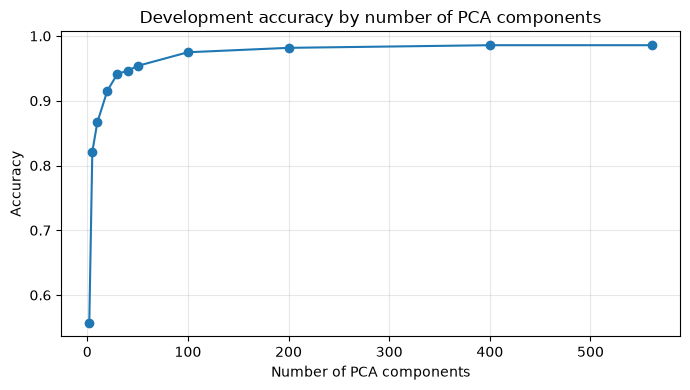

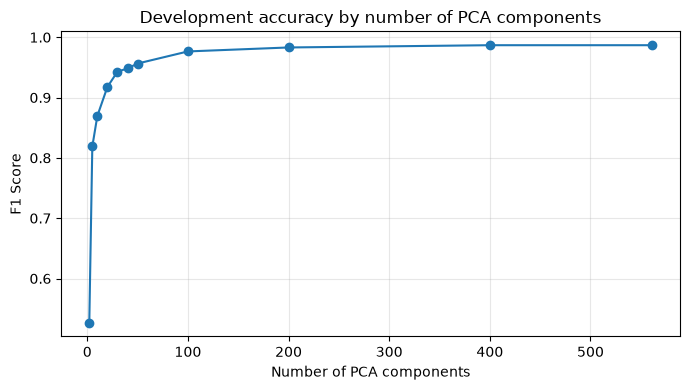

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# pca_model = LogisticRegression(max_iter=2000, random_state=42)
# pca_model.fit(X_train_pca_k, y_train)
# y_dev_pred_pca = pca_model.predict(X_dev_pca_k)

# print("Classification Report (PCA):\n", classification_report(y_dev, y_dev_pred_pca))
# print("Confusion Matrix (PCA):\n", confusion_matrix(y_dev, y_dev_pred_pca))
# print("Accuracy Score (PCA):\n", accuracy_score(y_dev, y_dev_pred_pca))

# try different values for K
component_counts = [2, 5, 10, 20, 30, 40, 50, 100,200,400, 561]  # You can adjust this list based on your needs
pca_accuracies = []
pca_predictions = []
pca_recalls = []
pca_f1_scores = []
pca_precisions = []
pca_models = {}
X_dev_pca = pca.transform(X_dev_scaled)
pca_training_times = []

for k in component_counts:
    start_time = perf_counter()
    model = LogisticRegression(max_iter=2000, random_state=42)
    model.fit(X_train_pca[:, :k], y_train)
    end_time = perf_counter()
    pca_models[k] = model
    y_dev_pred = model.predict(X_dev_pca[:, :k])
    pca_training_times.append(end_time - start_time)

    accuracy = accuracy_score(y_dev, y_dev_pred)
    recall = recall_score(y_dev, y_dev_pred, average="macro", zero_division=0)
    f1 = f1_score(y_dev, y_dev_pred, average="macro", zero_division=0)
    precision = precision_score(y_dev, y_dev_pred, average="macro", zero_division=0)

    pca_accuracies.append(accuracy)
    pca_recalls.append(recall)
    pca_f1_scores.append(f1)
    pca_precisions.append(precision)

results_df = pd.DataFrame({
    "Components": component_counts,
    "Accuracy": pca_accuracies,
    "Recall": pca_recalls,
    "F1 Score": pca_f1_scores,
    "Precision": pca_precisions,
    "Training Time (s)": pca_training_times
})
print(results_df)
plot_lines(
    results_df["Components"],
    {"PCA + logistic regression": results_df["Accuracy"]},
    title="Development accuracy by number of PCA components",
    xlabel="Number of PCA components",
    ylabel="Accuracy"
)

plot_lines(
    results_df["Components"],
    {"PCA + logistic regression": results_df["F1 Score"]},
    title="Development accuracy by number of PCA components",
    xlabel="Number of PCA components",
    ylabel="F1 Score"
)


## Train on Random Forest Selected Features

    Features  Accuracy    Recall  F1 Score  Training Time (s)
0          2  0.439837  0.402353  0.360546           0.106746
1          5  0.629504  0.611477  0.593182           0.174529
2         10  0.649218  0.635554  0.631093           0.239897
3         20  0.919782  0.919944  0.920593           0.182110
4         30  0.929980  0.930674  0.931353           0.310041
5         40  0.936778  0.939109  0.939182           0.453245
6         50  0.938137  0.940741  0.940695           0.483222
7        100  0.958532  0.960282  0.960501           0.693639
8        200  0.978246  0.979899  0.979760           0.880353
9        400  0.987763  0.988681  0.988721           0.957368
10       561  0.985724  0.986806  0.986825           1.005464


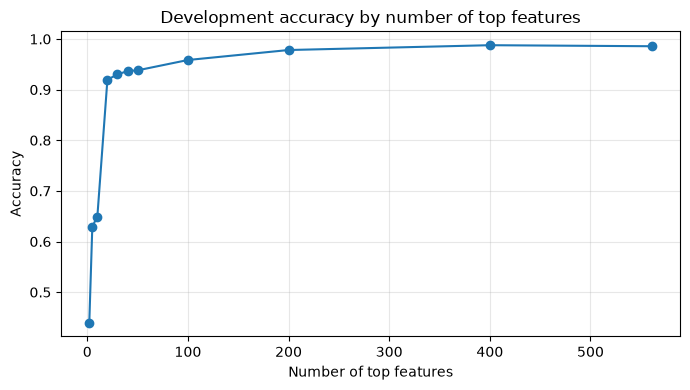

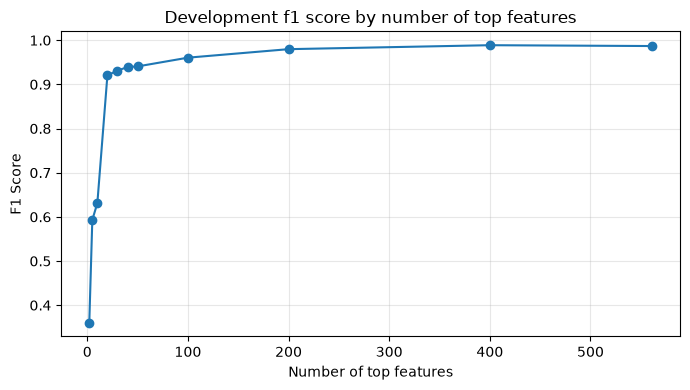

In [12]:
feature_counts = [2, 5, 10, 20, 30, 40, 50, 100,200,400, 561]  # You can adjust this list based on your needs
rf_accuracies = []
rf_predictions = []
rf_recalls = []
rf_f1_scores = []
selected_models = {}
selected_training_times = []

for n_features in feature_counts:
    top_indexes = feature_ranking[:n_features]
    
    X_train_k = X_train_scaled[:, top_indexes]
    X_dev_k = X_dev_scaled[:, top_indexes]

    rf_model = LogisticRegression(max_iter=2000, random_state=42)
    start_time = perf_counter()
    rf_model.fit(X_train_k, y_train)
    end_time = perf_counter()
    selected_models[n_features] = rf_model
    y_dev_pred = rf_model.predict(X_dev_k)
    selected_training_times.append(end_time - start_time)
    accuracy = accuracy_score(y_dev, y_dev_pred)
    recall = recall_score(y_dev, y_dev_pred, average="macro", zero_division=0)
    f1 = f1_score(y_dev, y_dev_pred, average="macro", zero_division=0)

    rf_accuracies.append(accuracy)
    rf_recalls.append(recall)
    rf_f1_scores.append(f1)

rf_results_df = pd.DataFrame({
    "Features": feature_counts,
    "Accuracy": rf_accuracies,
    "Recall": rf_recalls,
    "F1 Score": rf_f1_scores,
    "Training Time (s)": selected_training_times
})
print(rf_results_df)

plot_lines(
    rf_results_df["Features"],
    {"Random Forest + logistic regression": rf_results_df["Accuracy"]},
    title="Development accuracy by number of top features",
    xlabel="Number of top features",
    ylabel="Accuracy"
)

plot_lines(
    rf_results_df["Features"],
    {"Random Forest + logistic regression": rf_results_df["F1 Score"]},
    title="Development f1 score by number of top features",
    xlabel="Number of top features",
    ylabel="F1 Score"
)



## Evaluate on Test Data

In [13]:
pca_k = 200
selected_k = 200

X_test_pca_k = pca.transform(X_test_scaled)[:, :pca_k]
selected_indexes = feature_ranking[:selected_k]
X_test_selected = X_test_scaled[:, selected_indexes]

y_test_pred_full = logreg.predict(X_test_scaled)
y_test_pred_pca = pca_models[pca_k].predict(X_test_pca_k)
y_test_pred_selected = selected_models[selected_k].predict(X_test_selected)

for name, predictions in [
    ("Full features", y_test_pred_full),
    ("PCA", y_test_pred_pca),
    ("Selected features", y_test_pred_selected)
]:
    print(f"\n{name} model:")
    print("Classification Report:\n", classification_report(y_test, predictions))
    print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))
    print("Accuracy Score:\n", accuracy_score(y_test, predictions))


Full features model:
Classification Report:
                     precision    recall  f1-score   support

            LAYING       1.00      0.99      0.99       537
           SITTING       0.96      0.89      0.92       491
          STANDING       0.90      0.97      0.93       532
           WALKING       0.94      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
  WALKING_UPSTAIRS       0.96      0.95      0.95       471

          accuracy                           0.96      2947
         macro avg       0.96      0.95      0.96      2947
      weighted avg       0.96      0.96      0.96      2947

Confusion Matrix:
 [[531   0   6   0   0   0]
 [  1 437  51   0   0   2]
 [  0  18 514   0   0   0]
 [  0   0   0 492   4   0]
 [  0   0   2   7 395  16]
 [  0   0   0  24   1 446]]
Accuracy Score:
 0.9552086868001357

PCA model:
Classification Report:
                     precision    recall  f1-score   support

            LAYING       1.00      0

## Evaluate Training Times

In [14]:
timing_comparison = pd.DataFrame([
    {
        "Model": "All features",
        "Dimensions": 561,
        "Training Time (s)": logreg_training_time
    },
    {
        "Model": "PCA",
        "Dimensions": pca_k,
        "Training Time (s)": results_df.loc[
            results_df["Components"] == pca_k, "Training Time (s)"
        ].iloc[0]
    },
    {
        "Model": "Selected features",
        "Dimensions": selected_k,
        "Training Time (s)": rf_results_df.loc[
            rf_results_df["Features"] == selected_k, "Training Time (s)"
        ].iloc[0]
    }
])

display(timing_comparison)

,Model,Dimensions,Training Time (s)
0,All features,561,14.972826
1,PCA,200,0.770031
2,Selected features,200,0.880353
